In [1]:
# Import required libraries

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.datasets import load_breast_cancer
from sklearn.datasets import load_iris

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.cluster import KMeans

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score

In [3]:
#==========================
#Regression Performance
#==========================

# Load diabetes dataset

diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [4]:
# Train regression models

linear = LinearRegression()
ridge = Ridge(alpha=1)
lasso = Lasso(alpha=0.1)

linear.fit(X_train,y_train)
ridge.fit(X_train,y_train)
lasso.fit(X_train,y_train)

Lasso(alpha=0.1)

In [5]:
# Make predictions

linear_pred = linear.predict(X_test)

ridge_pred = ridge.predict(X_test)

lasso_pred = lasso.predict(X_test)

In [6]:
# Compare regression models

models = ["Linear","Ridge","Lasso"]

mae = [
    mean_absolute_error(y_test,linear_pred),
    mean_absolute_error(y_test,ridge_pred),
    mean_absolute_error(y_test,lasso_pred)
]

mse = [
    mean_squared_error(y_test,linear_pred),
    mean_squared_error(y_test,ridge_pred),
    mean_squared_error(y_test,lasso_pred)
]

rmse = [
    np.sqrt(mean_squared_error(y_test,linear_pred)),
    np.sqrt(mean_squared_error(y_test,ridge_pred)),
    np.sqrt(mean_squared_error(y_test,lasso_pred))
]

r2 = [
    r2_score(y_test,linear_pred),
    r2_score(y_test,ridge_pred),
    r2_score(y_test,lasso_pred)
]

print("Regression Performance")

for i in range(len(models)):
    print()
    print(models[i])
    print("MAE :",mae[i])
    print("MSE :",mse[i])
    print("RMSE :",rmse[i])
    print("R2 :",r2[i])

Regression Performance

Linear
MAE : 42.79409467959994
MSE : 2900.193628493482
RMSE : 53.85344583676593
R2 : 0.4526027629719195

Ridge
MAE : 46.13885766697452
MSE : 3077.41593882723
RMSE : 55.47446204180109
R2 : 0.41915292635986545

Lasso
MAE : 42.85442771664998
MSE : 2798.193485169719
RMSE : 52.897953506442185
R2 : 0.4718547867276227


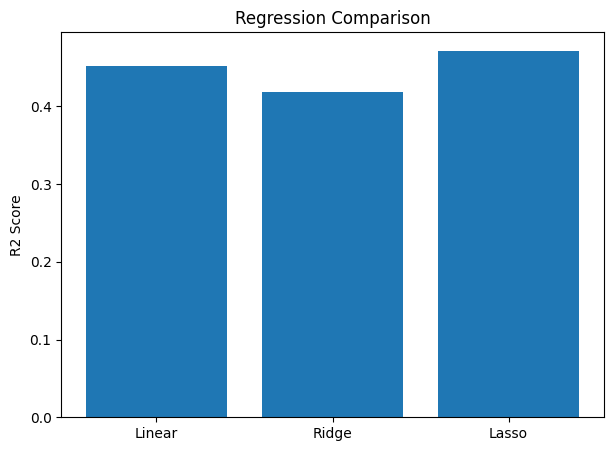

In [7]:
# Plot R2 Scores

plt.figure(figsize=(7,5))

plt.bar(models,r2)

plt.ylabel("R2 Score")

plt.title("Regression Comparison")

plt.show()

In [8]:
#==========================
#Classification Performance
#==========================

# Load breast cancer dataset

cancer = load_breast_cancer()

X = cancer.data

y = cancer.target

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
# Train classification models

logistic = LogisticRegression(max_iter=5000)

tree = DecisionTreeClassifier(random_state=42)

knn = KNeighborsClassifier()

bayes = GaussianNB()

logistic.fit(X_train,y_train)

tree.fit(X_train,y_train)

knn.fit(X_train,y_train)

bayes.fit(X_train,y_train)

GaussianNB()

In [10]:
# Predictions

log_pred = logistic.predict(X_test)

tree_pred = tree.predict(X_test)

knn_pred = knn.predict(X_test)

bayes_pred = bayes.predict(X_test)

In [11]:
# Compare classification models

models = [
    "Logistic",
    "Decision Tree",
    "KNN",
    "Naive Bayes"
]

accuracy = [
    accuracy_score(y_test,log_pred),
    accuracy_score(y_test,tree_pred),
    accuracy_score(y_test,knn_pred),
    accuracy_score(y_test,bayes_pred)
]

precision = [
    precision_score(y_test,log_pred),
    precision_score(y_test,tree_pred),
    precision_score(y_test,knn_pred),
    precision_score(y_test,bayes_pred)
]

recall = [
    recall_score(y_test,log_pred),
    recall_score(y_test,tree_pred),
    recall_score(y_test,knn_pred),
    recall_score(y_test,bayes_pred)
]

f1 = [
    f1_score(y_test,log_pred),
    f1_score(y_test,tree_pred),
    f1_score(y_test,knn_pred),
    f1_score(y_test,bayes_pred)
]

roc = [
    roc_auc_score(y_test,log_pred),
    roc_auc_score(y_test,tree_pred),
    roc_auc_score(y_test,knn_pred),
    roc_auc_score(y_test,bayes_pred)
]

for i in range(len(models)):

    print()

    print(models[i])

    print("Accuracy :",accuracy[i])

    print("Precision :",precision[i])

    print("Recall :",recall[i])

    print("F1 Score :",f1[i])

    print("ROC AUC :",roc[i])


Logistic
Accuracy : 0.956140350877193
Precision : 0.9459459459459459
Recall : 0.9859154929577465
F1 Score : 0.9655172413793104
ROC AUC : 0.9464461185718965

Decision Tree
Accuracy : 0.9473684210526315
Precision : 0.9577464788732394
Recall : 0.9577464788732394
F1 Score : 0.9577464788732394
ROC AUC : 0.9439895185063871

KNN
Accuracy : 0.956140350877193
Precision : 0.9342105263157895
Recall : 1.0
F1 Score : 0.9659863945578231
ROC AUC : 0.9418604651162791

Naive Bayes
Accuracy : 0.9736842105263158
Precision : 0.9594594594594594
Recall : 1.0
F1 Score : 0.9793103448275862
ROC AUC : 0.9651162790697674


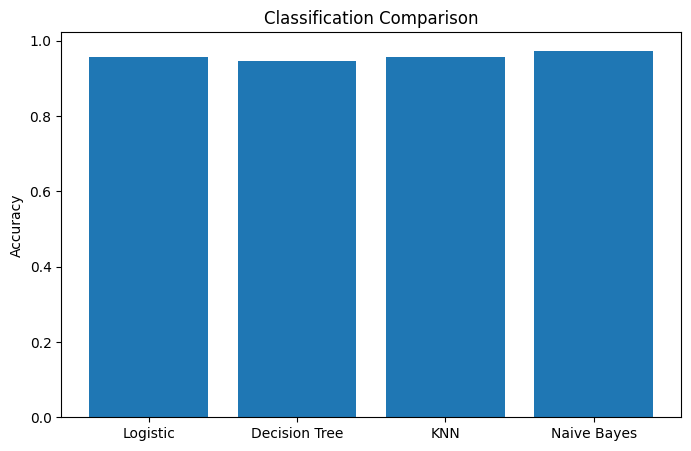

In [12]:
# Accuracy comparison

plt.figure(figsize=(8,5))

plt.bar(models,accuracy)

plt.ylabel("Accuracy")

plt.title("Classification Comparison")

plt.show()

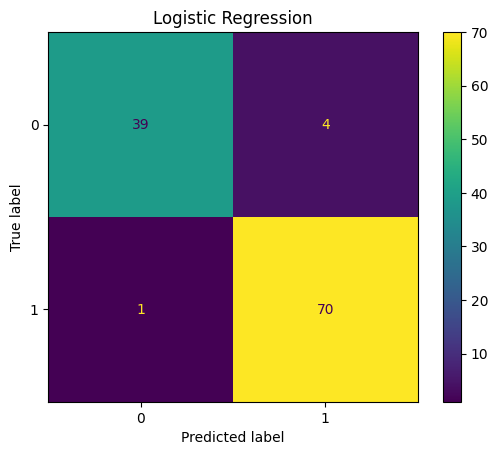

In [13]:
# Confusion Matrix

cm = confusion_matrix(y_test,log_pred)

ConfusionMatrixDisplay(cm).plot()

plt.title("Logistic Regression")

plt.show()

In [14]:
#==========================
#Clustering Performance
#==========================

# Load iris dataset

iris = load_iris()

X = iris.data

In [15]:
# Train KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

labels = kmeans.fit_predict(X)

In [16]:
# Calculate clustering metrics

silhouette = silhouette_score(
    X,
    labels
)

davies = davies_bouldin_score(
    X,
    labels
)

calinski = calinski_harabasz_score(
    X,
    labels
)

print("Silhouette Score :",silhouette)

print("Davies Bouldin Index :",davies)

print("Calinski Harabasz Index :",calinski)

Silhouette Score : 0.551191604619592
Davies Bouldin Index : 0.6660385791628493
Calinski Harabasz Index : 561.5937320156642


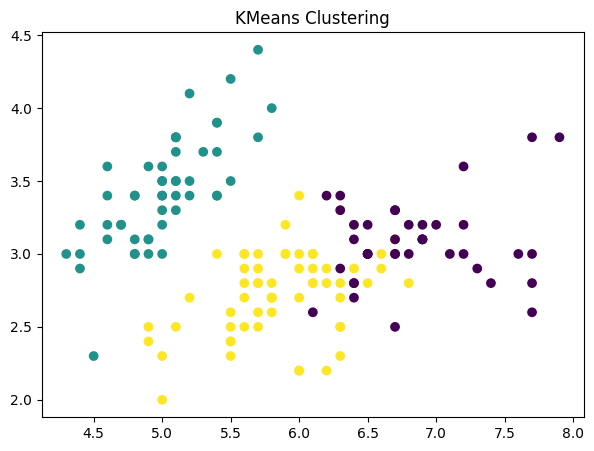

In [17]:
# Plot clustering

plt.figure(figsize=(7,5))

plt.scatter(
    X[:,0],
    X[:,1],
    c=labels
)

plt.title("KMeans Clustering")

plt.show()

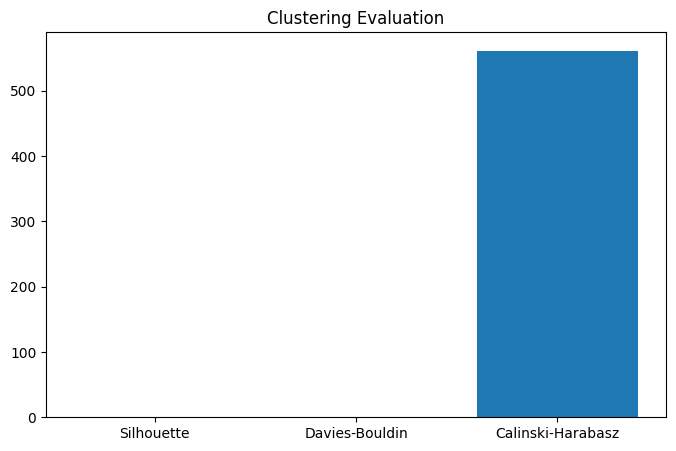

In [18]:
# Display clustering metrics

metrics = [
    "Silhouette",
    "Davies-Bouldin",
    "Calinski-Harabasz"
]

values = [
    silhouette,
    davies,
    calinski
]

plt.figure(figsize=(8,5))

plt.bar(metrics,values)

plt.title("Clustering Evaluation")

plt.show()